# Imports

In [1]:
# stop - UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
import os
os.environ["OMP_NUM_THREADS"] = "1"


from utils import *



import pandas as pd
import numpy as np
from sklearn.mixture import GaussianMixture
from scipy.stats import norm

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Setup

In [6]:
##############################
# Read Dataset into Dataframe
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'

# structural zones for iteration
structural_zones = ['MDHSZ', 'GS', 'CBSZ', 'CMZI']

# type of grouping
group_type = 'gmm'

# output path for interpretation
output_dir = r'../results'


timeline = [210, 450]
bar_width=0.4
gap=0.3


##### read into df...
df = pd.read_csv(clean_path)

# mask for garnet/cordierite lithologies (optional)...
# mask = (df['zone'] == 'MDHSZ') | (df['zone'] == 'GS') | (df['zone'] == 'CBSZ') | (df['zone'] == 'CMZI') & (df['garnet'] == 1)
mask = (df['zone'] == 'MDHSZ') | (df['zone'] == 'GS') | (df['zone'] == 'CBSZ') | (df['zone'] == 'CMZI') & (df['cordierite'] == 1)
df = df[mask]

df.sort_values('error', inplace=True)
df.reset_index(inplace=True)


df.head()

,level_0,index,sample,zone,mnz,texture,texture_chem,n,age,error,...,Er2O3,Tm2O3,Yb2O3,SO3,PbO,percent,lree,HREE,garnet,cordierite
0,2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.784962,...,0.014718,0.009812,0.009812,0.020605,0.079477,0.220495,61.972776,1.588568,1,0
1,1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.789124,...,0.009937,0.019969,0.009937,0.018184,0.132687,0.256926,57.520514,0.670830,1,0
2,3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.346540,...,0.009748,0.009748,0.009748,0.016339,0.082968,0.450800,61.526147,1.376610,1,0
3,4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.408622,...,0.009641,0.060215,0.009641,0.014777,0.085454,0.398772,60.699177,1.389823,1,1
4,6,145,P14-005A-5B,CBSZ,m11,core,Y depleted core,NaN,360.00,1.446959,...,0.009646,0.009646,0.009646,0.012540,0.080065,0.401933,61.707991,1.223163,1,0


# Gaussian Mixture Model

## Determine number of Components

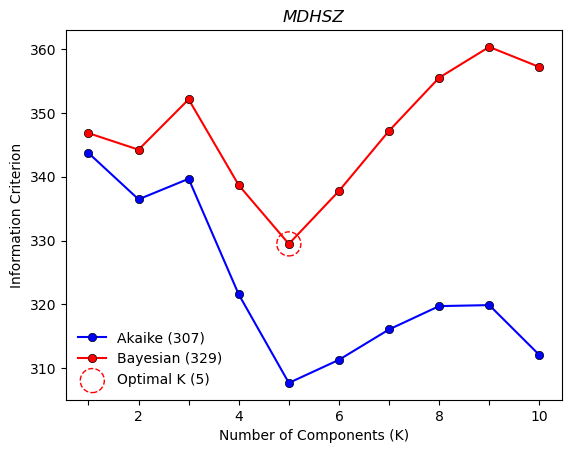

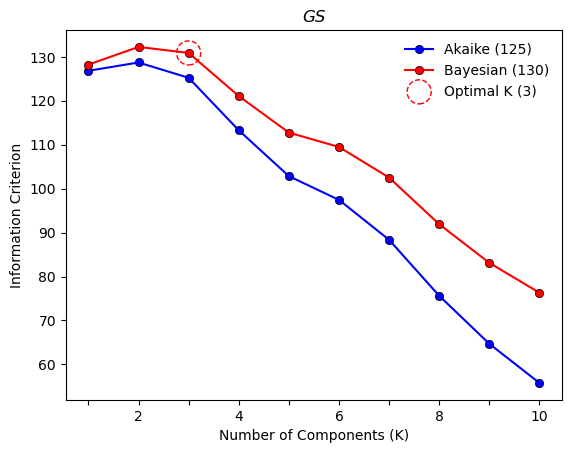

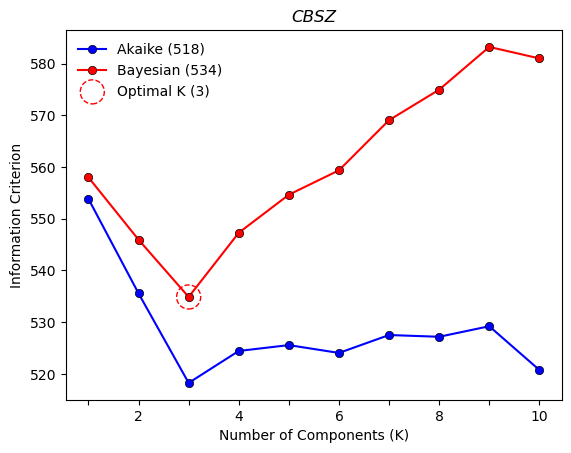

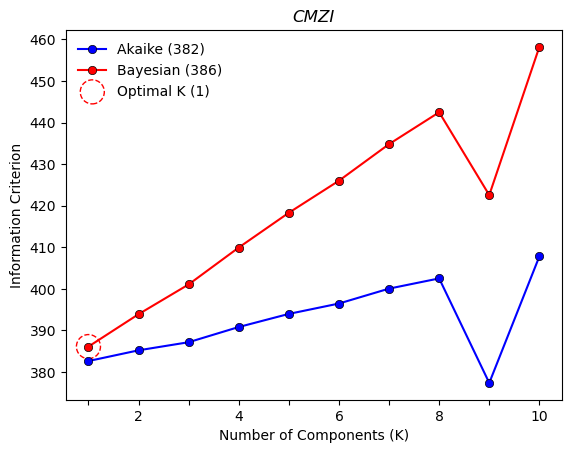

In [7]:

optimal_components = {}



for idx, zone in enumerate(structural_zones):

    df_subset = df[df['zone']==zone].copy()
    ages = df_subset['age'].to_numpy().reshape(-1,1)
    components = np.arange(1, 11, 1)
    aic = []
    bic = []
    
    for k in components:

        gm = GaussianMixture(n_components=k, covariance_type="full", n_init=10, random_state=111).fit(ages)
        aic.append(gm.aic(ages))
        bic.append(gm.bic(ages))

    aic = np.asarray(aic, dtype=float)
    bic = np.asarray(bic, dtype=float)

    # optimal_k = relative_drop_gmm_k(aic, bic)
    optimal_k = relative_drop_gmm_k(bic, k_prior=6)
    optimal_components[zone] = optimal_k

    fig, ax = plt.subplots()


    ax.plot(components, aic, color='blue', marker='o', markeredgecolor='k', markeredgewidth=0.5, label=f"Akaike ({int(aic[optimal_k-1])})")
    ax.plot(components, bic, color='red', marker='o', markeredgecolor='k', markeredgewidth=0.5, label=f"Bayesian ({int(bic[optimal_k-1])})")
    ax.scatter(components[optimal_k-1], bic[optimal_k-1], edgecolors='red', facecolors='none', linestyle='--', s=300, label=f"Optimal K ({optimal_k})")


    ax.legend(loc='best', frameon=False)
    ax.set_xticks(np.arange(1,11,1))
    ax.set_xticklabels(str(i) if i%2==0 else '' for i in np.arange(1,11,1))
    ax.set_xlabel('Number of Components (K)')
    ax.set_ylabel('Information Criterion')
    ax.set_title(zone, style='italic')

    output_path = f"{output_dir}/{group_type}_bic_{zone}_CRD"
    plt.savefig(output_path + '.png', dpi=300, pad_inches=0, bbox_inches='tight')
    plt.savefig(output_path + '.svg', dpi=300, pad_inches=0, bbox_inches='tight')

    plt.show()



## Final Cluster Labels

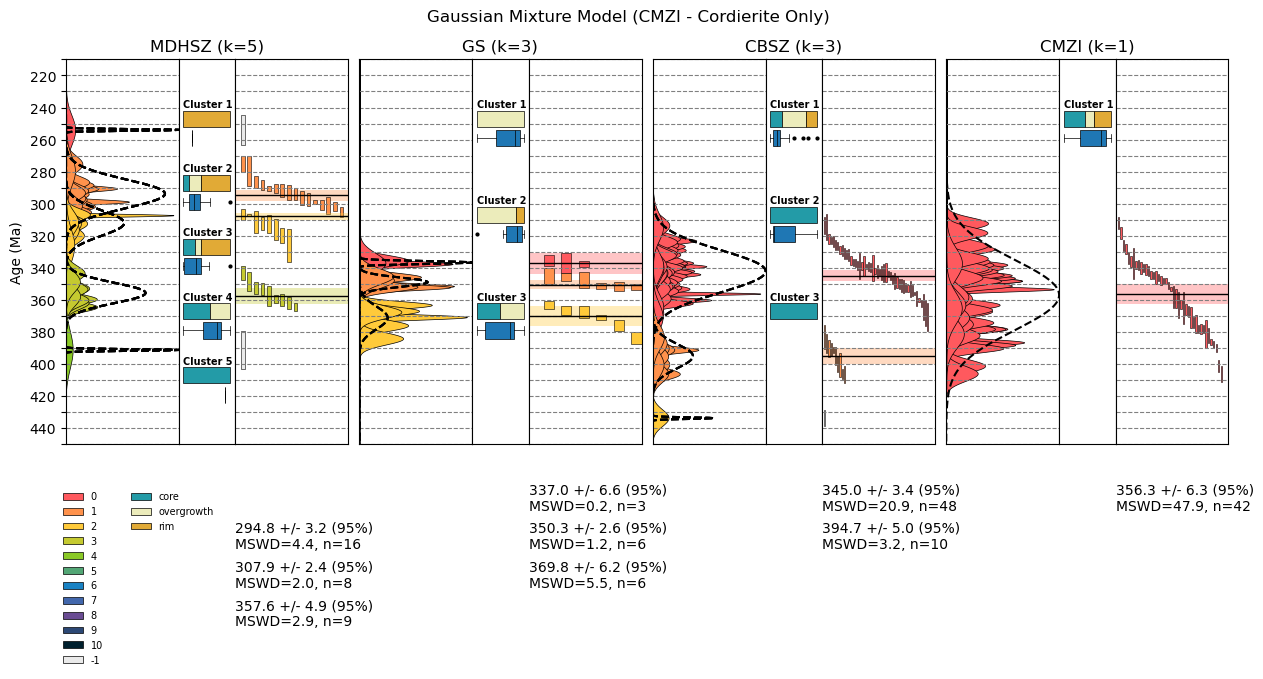

In [8]:


##### Plot figure...

fig = plt.figure(figsize=(15, 5))
width_ratios = [1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0]
gs = GridSpec(nrows=1, ncols=15, figure=fig, wspace=0, width_ratios=width_ratios)

# define axes - left triplet (A), spacer (hidden), right triplet (B)...
axA_1 = fig.add_subplot(gs[0, 0])
axA_2 = fig.add_subplot(gs[0, 1], sharey=axA_1)
axA_3 = fig.add_subplot(gs[0, 2], sharey=axA_1)
ax_sp1 = fig.add_subplot(gs[0, 3])                 # spacer
axB_1 = fig.add_subplot(gs[0, 4], sharey=axA_1)
axB_2 = fig.add_subplot(gs[0, 5], sharey=axA_1)
axB_3 = fig.add_subplot(gs[0, 6], sharey=axA_1)
ax_sp2 = fig.add_subplot(gs[0, 7])                 # spacer
axC_1 = fig.add_subplot(gs[0, 8], sharey=axA_1)
axC_2 = fig.add_subplot(gs[0, 9], sharey=axA_1)
axC_3 = fig.add_subplot(gs[0, 10], sharey=axA_1)
ax_sp3 = fig.add_subplot(gs[0, 11])                 # spacer
axD_1 = fig.add_subplot(gs[0, 12], sharey=axA_1)
axD_2 = fig.add_subplot(gs[0, 13], sharey=axA_1)
axD_3 = fig.add_subplot(gs[0, 14], sharey=axA_1)

# hide spacer axes...
ax_sp1.axis("off")
ax_sp2.axis("off")
ax_sp3.axis("off")

axA_1.set_ylim(450, 210)

panel1_max = [0.0, 0.0, 0.0, 0.0]
panel2_max = [0.0, 0.0, 0.0, 0.0]
panel3_max = [0.0, 0.0, 0.0, 0.0]


# iterate through structural zones...
for idx, zone in enumerate(structural_zones):

    df_subset = df.loc[df['zone']==zone].copy()
    df_gmm, comp, time, mix = gmm_processing(df_subset, optimal_components[zone])
    num_components = len(df_gmm['labels'].unique())
    component_labels = df_gmm['labels'].unique()
    y_max = df_gmm['Y2O3'].max()


    # iterate through each cluster label...
    for k, component in enumerate(component_labels):

        df_gmm_subset = df_gmm.loc[df_gmm['labels'] == component].copy()
        spacing = (450-210) / (num_components + 1)
        center = 240 + (k * spacing)


        # MDHSZ...
        if idx==0:
            sample_max = plot_samples_panel(df_gmm_subset, axA_1, 'labels', age_group_colors, label_bool=True)

            axA_1B = axA_1.twiny()
            plot_components_panel(axA_1B, comp, time)


            plot_ageinterp_panel(df_gmm_subset, axA_3, k, age_group_colors, ci='95%')

            texture_counts = df_gmm_subset['texture'].value_counts().to_dict()
            texture_counts = dict(sorted(texture_counts.items()))
            horizontal_stack(axA_2, k, center, texture_counts, texture_colors, df_gmm_subset['Y2O3'].to_numpy())
            
            axA_2.set_title(f"{zone} (k={num_components})", loc='center')

            # plot age group information below plot...
            ages = df_gmm_subset['age'].to_numpy()
            errors = df_gmm_subset['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='95%')
            label = ''
            if stats['n'] >= 3:
                # label = f"\n{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
            axA_3.text(0, -0.1-(k/10), label, transform=axA_3.transAxes, fontsize=10, ha='left', va='top')


        # GS...
        if idx==1:
            sample_max = plot_samples_panel(df_gmm_subset, axB_1, 'labels', age_group_colors, label_bool=False)

            axB_1B = axB_1.twiny()
            plot_components_panel(axB_1B, comp, time)

            plot_ageinterp_panel(df_gmm_subset, axB_3, k, age_group_colors, ci='95%')

            texture_counts = df_gmm_subset['texture'].value_counts().to_dict()
            texture_counts = dict(sorted(texture_counts.items()))
            horizontal_stack(axB_2, k, center, texture_counts, texture_colors, df_gmm_subset['Y2O3'].to_numpy())
            
            axB_2.set_title(f"{zone} (k={num_components})", loc='center')

            # plot age group information below plot...
            ages = df_gmm_subset['age'].to_numpy()
            errors = df_gmm_subset['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='95%')
            label = ''
            if stats['n'] >= 3:
                # label = f"\n{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
            axB_3.text(0, -0.1-(k/10), label, transform=axB_3.transAxes, fontsize=10, ha='left', va='top')


        
        # CBSZ...
        if idx==2:
            sample_max = plot_samples_panel(df_gmm_subset, axC_1, 'labels', age_group_colors, label_bool=False)

            axC_1B = axC_1.twiny()
            plot_components_panel(axC_1B, comp, time)

            plot_ageinterp_panel(df_gmm_subset, axC_3, k, age_group_colors, ci='95%')

            texture_counts = df_gmm_subset['texture'].value_counts().to_dict()
            texture_counts = dict(sorted(texture_counts.items()))
            horizontal_stack(axC_2, k, center, texture_counts, texture_colors, df_gmm_subset['Y2O3'].to_numpy())
            
            axC_2.set_title(f"{zone} (k={num_components})", loc='center')

            # plot age group information below plot...
            ages = df_gmm_subset['age'].to_numpy()
            errors = df_gmm_subset['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='95%')
            label = ''
            if stats['n'] >= 3:
                # label = f"\n{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
            axC_3.text(0, -0.1-(k/10), label, transform=axC_3.transAxes, fontsize=10, ha='left', va='top')



        # CMZI...
        if idx==3:
            sample_max = plot_samples_panel(df_gmm_subset, axD_1, 'labels', age_group_colors, label_bool=False)

            axD_1B = axD_1.twiny()
            plot_components_panel(axD_1B, comp, time)

            plot_ageinterp_panel(df_gmm_subset, axD_3, k, age_group_colors, ci='95%')

            texture_counts = df_gmm_subset['texture'].value_counts().to_dict()
            texture_counts = dict(sorted(texture_counts.items()))
            horizontal_stack(axD_2, k, center, texture_counts, texture_colors, df_gmm_subset['Y2O3'].to_numpy())
            
            axD_2.set_title(f"{zone} (k={num_components})", loc='center')

            # plot age group information below plot...
            ages = df_gmm_subset['age'].to_numpy()
            errors = df_gmm_subset['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='95%')
            label = ''
            if stats['n'] >= 3:
                # label = f"\n{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
            axD_3.text(0, -0.1-(k/10), label, transform=axD_3.transAxes, fontsize=10, ha='left', va='top')



        panel1_max[idx] = max(panel1_max[idx], sample_max)
    panel3_max[idx] = df_gmm.value_counts('labels').max()




# hard-pin the inverted y on all shared siblings
for a in axA_1.get_shared_y_axes().get_siblings(axA_1):
    a.set_ylim(450, 210)
    a.set_autoscale_on(False)

# also pin the memoized twins so they cannot drift
for mid in (axA_2, axB_2, axC_2, axD_2):
    if hasattr(mid, "_box_twin"):
        mid._box_twin.set_ylim(450, 210)
        mid._box_twin.set_autoscale_on(False)



axA_1.set_xlim(0, panel1_max[0] * 1.05)
axA_3.set_xlim(0, panel3_max[0] * (bar_width + gap + 0.05))

axB_1.set_xlim(0, panel1_max[1] * 1.05)
axB_3.set_xlim(0, panel3_max[1] * (bar_width + gap + 0.05))

axC_1.set_xlim(0, panel1_max[2] * 1.05)
axC_3.set_xlim(0, panel3_max[2] * (bar_width + gap + 0.05))

axD_1.set_xlim(0, panel1_max[3] * 1.05)
axD_3.set_xlim(0, panel3_max[3] * (bar_width + gap + 0.05))



# create legend...

patches = []
for k,v in age_group_colors.items():
    patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))

# create legend for texture
axA_1.legend(patches, [l.get_label() for l in patches], loc='upper left', bbox_to_anchor=(-0.1,-0.1), frameon=False, fontsize=7)


# patches for texture...
patches = []
for k,v in texture_colors.items():
    patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))
axA_2.legend(patches, [l.get_label() for l in patches], loc='upper left', bbox_to_anchor=(-1,-0.1), frameon=False, fontsize=7)



plt.suptitle('Gaussian Mixture Model (CMZI - Cordierite Only)')
output_path = f"{output_dir}/{group_type}_interpretation_CRD"
plt.savefig(output_path + '.png', dpi=300, pad_inches=0, bbox_inches='tight')
plt.savefig(output_path + '.svg', dpi=300, pad_inches=0, bbox_inches='tight')

plt.show()